# Assignment 5 — Task 1: Bidirectional Transformer Encoder for AG News Classification

**Course:** Deep Learning  
**Task:** Classify news headlines and descriptions into **World, Sports, Business, and Sci/Tech** using a BERT-style, bidirectional Transformer encoder implemented from first principles.

This notebook is designed for **Google Colab**. It builds the tokenizer, vocabulary, positional encodings, multi-head self-attention, encoder blocks, and classification head using PyTorch tensor operations. It does **not** use a pretrained BERT model or `torch.nn.TransformerEncoder`.

### What this notebook does
1. Loads `train.csv` and `test.csv` from the AG News Kaggle dataset.
2. Creates a stratified, balanced training subset of exactly **20,000 rows** (5,000 per category).
3. Builds a word-level vocabulary of 15,000 entries including `[PAD]`, `[UNK]`, and `[CLS]`.
4. Prepends `[CLS]`, truncates/pads every sequence to 64 tokens, and creates an additive key-padding mask with values `0` and `-inf`.
5. By default, runs five representative experiments that isolate depth, head count, model width, and positional encoding. The full 16-configuration grid remains available by changing one setting.
6. Reports test accuracy and Macro F1, plots loss curves and a confusion matrix, and visualizes the final layer's `[CLS]` attention across heads.

> **Colab setup:** Select **Runtime → Change runtime type → T4 GPU** (or another GPU) before running. Run the cells from top to bottom. The default fast experiment runs five configurations for up to three epochs each. To run all 16 combinations for the full comparison, set `FAST_EXPERIMENT = False` in the configuration cell. The test split is evaluated only once, after selecting the best configuration by validation Macro F1.

## 1. Install/import libraries

PyTorch is used for the model. Scikit-learn is used only for stratified splitting and evaluation metrics; the Transformer itself is implemented below.

In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn tqdm

import os
import re
import io
import gc
import math
import time
import json
import random
import zipfile
from pathlib import Path
from collections import Counter
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tqdm.auto import tqdm

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 2. Reproducibility and experiment configuration

The complete grid is:

- Transformer depth: `L ∈ {2, 4}`
- Attention heads: `h ∈ {2, 4}`
- Model width: `d_model ∈ {64, 128}`
- Positional encoding: learned or fixed sinusoidal

This gives **16 configurations**. The required convergence rule is applied after every epoch: stop when the absolute change in average training loss between consecutive epochs is below `1e-4`. `MAX_EPOCHS` is a safety cap so the notebook cannot train indefinitely.

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Assignment settings
BALANCED_TRAIN_SIZE = 20_000
SAMPLES_PER_CLASS = 5_000
VOCAB_SIZE = 15_000          # Must be between 10,000 and 20,000
MAX_SEQ_LEN = 64
NUM_CLASSES = 4
LABEL_NAMES = ["World", "Sports", "Business", "Sci/Tech"]

# Training settings
BATCH_SIZE = 128
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
DROPOUT = 0.10
MAX_EPOCHS = 3                # Fast default; set to 5-10 for a longer final run
CONVERGENCE_TOL = 1e-4
NUM_WORKERS = 2 if torch.cuda.is_available() else 0
USE_AMP = torch.cuda.is_available()  # mixed precision on supported Colab GPUs

# Five representative configurations: baseline + change one factor at a time.
# This is much faster than training all 16 combinations and still gives direct
# comparisons for depth, head count, model width, and positional encoding.
FAST_CONFIGS = [
    {"num_layers": 2, "num_heads": 2, "d_model": 64,  "positional": "learned"},      # baseline
    {"num_layers": 4, "num_heads": 2, "d_model": 64,  "positional": "learned"},      # depth
    {"num_layers": 2, "num_heads": 4, "d_model": 64,  "positional": "learned"},      # heads
    {"num_layers": 2, "num_heads": 2, "d_model": 128, "positional": "learned"},      # width
    {"num_layers": 2, "num_heads": 2, "d_model": 64,  "positional": "sinusoidal"},  # position
]

# Full grid from the assignment (16 configurations).
FULL_CONFIGS = [
    {"num_layers": L, "num_heads": H, "d_model": D, "positional": P}
    for L, H, D, P in product([2, 4], [2, 4], [64, 128], ["learned", "sinusoidal"])
]

FAST_EXPERIMENT = True  # Set False to run the full 16-configuration grid.
if FAST_EXPERIMENT:
    CONFIGS = FAST_CONFIGS
else:
    CONFIGS = FULL_CONFIGS
    MAX_EPOCHS = 5  # Increase further if Colab runtime allows.

print("Experiment mode:", "FAST (5 configs)" if FAST_EXPERIMENT else "FULL (16 configs)")
print("Number of configurations:", len(CONFIGS))
print("Maximum epochs per configuration:", MAX_EPOCHS)
print("Device:", DEVICE)


Experiment mode: FAST (5 configs)
Number of configurations: 5
Maximum epochs per configuration: 3
Device: cuda


## 3. Get the AG News dataset

Dataset source: [AG News Classification Dataset on Kaggle](https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset).

Download the dataset ZIP from Kaggle and upload it in the next cell, **or** upload both `train.csv` and `test.csv` together. If you use the Kaggle API instead, download/unzip the dataset into `/content/ag_news` and then continue.

In [3]:
DATA_DIR = Path("/content/ag_news")
DATA_DIR.mkdir(parents=True, exist_ok=True)


def find_csv_pair(root: Path):
    train_matches = [p for p in root.rglob("*") if p.is_file() and p.name.lower() == "train.csv"]
    test_matches  = [p for p in root.rglob("*") if p.is_file() and p.name.lower() == "test.csv"]
    if train_matches and test_matches:
        # Select the first matching pair; Kaggle archives normally contain one pair.
        return train_matches[0], test_matches[0]
    return None, None

train_path, test_path = find_csv_pair(DATA_DIR)

if train_path is None or test_path is None:
    try:
        from google.colab import files
        print("Upload the Kaggle ZIP, or select both train.csv and test.csv files.")
        uploaded = files.upload()
        for filename, payload in uploaded.items():
            payload_bytes = bytes(payload)
            if filename.lower().endswith(".zip") or zipfile.is_zipfile(io.BytesIO(payload_bytes)):
                with zipfile.ZipFile(io.BytesIO(payload_bytes)) as zf:
                    zf.extractall(DATA_DIR)
            else:
                destination = DATA_DIR / Path(filename).name
                destination.write_bytes(payload_bytes)
        train_path, test_path = find_csv_pair(DATA_DIR)
    except ImportError:
        print("Google Colab upload helper is unavailable. Put train.csv and test.csv inside", DATA_DIR)
        train_path, test_path = find_csv_pair(DATA_DIR)

if train_path is None or test_path is None:
    raise FileNotFoundError(
        f"Could not find both train.csv and test.csv under {DATA_DIR}. "
        "Upload the Kaggle ZIP or both CSV files, then rerun this cell."
    )

print("Training CSV:", train_path)
print("Test CSV:", test_path)

Upload the Kaggle ZIP, or select both train.csv and test.csv files.


Saving archive (2).zip to archive (2).zip
Training CSV: /content/ag_news/train.csv
Test CSV: /content/ag_news/test.csv


## 4. Read and normalize the CSV files

The Kaggle file may be saved either with column headers (`Class Index`, `Title`, `Description`) or without headers. The loader below supports both. The expected AG News class mapping is `1=World`, `2=Sports`, `3=Business`, and `4=Sci/Tech`.

In [4]:
HEADER_NAMES = {"class index", "label", "class", "category"}
TEXT_LABEL_MAP = {
    "world": 0,
    "sports": 1,
    "sport": 1,
    "business": 2,
    "sci/tech": 3,
    "sci-tech": 3,
    "science/technology": 3,
    "science & technology": 3,
    "science technology": 3,
    "technology": 3,
}


def _clean_column_name(name):
    return re.sub(r"[^a-z0-9]+", " ", str(name).strip().lower()).strip()


def read_ag_news_csv(path: Path) -> pd.DataFrame:
    raw = pd.read_csv(path, header=None, encoding="utf-8", encoding_errors="replace")
    first = str(raw.iloc[0, 0]).strip().lower()
    has_header = (first in HEADER_NAMES) or (not re.fullmatch(r"\d+", first))

    if has_header:
        df = pd.read_csv(path, encoding="utf-8", encoding_errors="replace")
        col_lookup = {_clean_column_name(c): c for c in df.columns}
        label_col = next((col_lookup[k] for k in ["class index", "label", "class", "category"] if k in col_lookup), df.columns[0])
        title_col = next((col_lookup[k] for k in ["title", "headline"] if k in col_lookup), None)
        desc_col = next((col_lookup[k] for k in ["description", "content", "text"] if k in col_lookup), None)
        if title_col is None and len(df.columns) >= 2:
            title_col = df.columns[1]
        if desc_col is None and len(df.columns) >= 3:
            desc_col = df.columns[2]
        if title_col is None or desc_col is None:
            raise ValueError(f"Could not identify title/description columns in {path}. Columns: {list(df.columns)}")
        df = df[[label_col, title_col, desc_col]].copy()
        df.columns = ["label_raw", "title", "description"]
    else:
        if raw.shape[1] < 3:
            raise ValueError(f"Expected at least 3 columns in {path}, found {raw.shape[1]}.")
        df = raw.iloc[:, :3].copy()
        df.columns = ["label_raw", "title", "description"]

    numeric_labels = pd.to_numeric(df["label_raw"], errors="coerce")
    if numeric_labels.notna().all():
        unique_values = set(numeric_labels.astype(int).unique().tolist())
        if unique_values.issubset({1, 2, 3, 4}):
            df["label"] = numeric_labels.astype(int) - 1
        elif unique_values.issubset({0, 1, 2, 3}):
            df["label"] = numeric_labels.astype(int)
        else:
            raise ValueError(f"Unexpected numeric labels in {path}: {sorted(unique_values)}")
    else:
        mapped = df["label_raw"].astype(str).str.strip().str.lower().map(TEXT_LABEL_MAP)
        if mapped.isna().any():
            bad = df.loc[mapped.isna(), "label_raw"].astype(str).unique()[:10]
            raise ValueError(f"Unrecognized labels in {path}: {bad}")
        df["label"] = mapped.astype(int)

    df["title"] = df["title"].fillna("").astype(str)
    df["description"] = df["description"].fillna("").astype(str)
    df["text"] = (df["title"].str.strip() + " " + df["description"].str.strip()).str.strip()
    df = df[df["text"].str.len() > 0].reset_index(drop=True)
    return df[["text", "label"]]

train_full = read_ag_news_csv(train_path)
test_df = read_ag_news_csv(test_path)

print("Full training split:", train_full.shape)
print("Official test split:", test_df.shape)
print("Training class counts:\n", train_full["label"].value_counts().sort_index())
print("Test class counts:\n", test_df["label"].value_counts().sort_index())

Full training split: (120000, 2)
Official test split: (7600, 2)
Training class counts:
 label
0    30000
1    30000
2    30000
3    30000
Name: count, dtype: int64
Test class counts:
 label
0    1900
1    1900
2    1900
3    1900
Name: count, dtype: int64


## 5. Create the balanced 20,000-row training subset

Exactly 5,000 training examples are sampled from each of the four classes, giving **20,000 actual training examples**. To monitor training without taking any of those 20,000 examples away, a separate validation set of 2,000 examples (500 per class) is sampled from the remaining rows of `train.csv`. The official `test.csv` split remains untouched until evaluation.

In [5]:
class_counts = train_full["label"].value_counts()
missing_or_small = {LABEL_NAMES[k]: int(class_counts.get(k, 0)) for k in range(NUM_CLASSES) if class_counts.get(k, 0) < SAMPLES_PER_CLASS}
if missing_or_small:
    raise ValueError(
        "The provided train.csv does not have at least 5,000 examples in every class. "
        f"Insufficient counts: {missing_or_small}"
    )

balanced_df = (
    train_full.groupby("label", group_keys=False)
    .sample(n=SAMPLES_PER_CLASS, random_state=SEED)
    .sample(frac=1.0, random_state=SEED)
)

# Validation is sampled from the remaining original training rows, so no examples
# are removed from the required 20,000-example balanced training subset.
remaining_train_rows = train_full.drop(index=balanced_df.index)
val_df = (
    remaining_train_rows.groupby("label", group_keys=False)
    .sample(n=500, random_state=SEED)
)
train_df = balanced_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

assert len(train_df) == BALANCED_TRAIN_SIZE
print("Balanced training subset:", len(balanced_df))
print("Training examples used for gradient updates:", len(train_df))
print("Validation examples:", len(val_df))
print("Balanced training class counts:\n", train_df["label"].value_counts().sort_index())
print("Validation class counts:\n", val_df["label"].value_counts().sort_index())

Balanced training subset: 20000
Training examples used for gradient updates: 20000
Validation examples: 2000
Balanced training class counts:
 label
0    5000
1    5000
2    5000
3    5000
Name: count, dtype: int64
Validation class counts:
 label
0    500
1    500
2    500
3    500
Name: count, dtype: int64


## 6. Tokenization and vocabulary construction

A simple, reproducible word-level tokenizer is used. The vocabulary is built **only from the training portion** to avoid validation/test leakage. The three required special tokens occupy fixed IDs:

- `[PAD] = 0`
- `[UNK] = 1`
- `[CLS] = 2`

The vocabulary is capped at 15,000 tokens, which is within the required 10,000–20,000 range. Each encoded sequence starts with `[CLS]` and has a total length of 64.

In [6]:
PAD_TOKEN = "[PAD]"
UNK_TOKEN = "[UNK]"
CLS_TOKEN = "[CLS]"
PAD_ID, UNK_ID, CLS_ID = 0, 1, 2
SPECIAL_TOKENS = [PAD_TOKEN, UNK_TOKEN, CLS_TOKEN]


def tokenize(text):
    # Keep words, contractions, numbers, and punctuation as separate tokens.
    return re.findall(r"[A-Za-z0-9]+(?:['’][A-Za-z0-9]+)?|[^\w\s]", str(text).lower())

counter = Counter()
for text in tqdm(train_df["text"].tolist(), desc="Building vocabulary"):
    counter.update(tokenize(text))

vocab = {token: idx for idx, token in enumerate(SPECIAL_TOKENS)}
for token, _ in counter.most_common(VOCAB_SIZE - len(SPECIAL_TOKENS)):
    if token not in vocab:
        vocab[token] = len(vocab)

id_to_token = {idx: token for token, idx in vocab.items()}
print("Vocabulary size:", len(vocab))
print("Special token IDs:", {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID, CLS_TOKEN: CLS_ID})
assert 10_000 <= len(vocab) <= 20_000, "Vocabulary size must be in the required range."


def encode_text(text, max_length=MAX_SEQ_LEN):
    tokens = tokenize(text)
    token_ids = [CLS_ID] + [vocab.get(tok, UNK_ID) for tok in tokens[: max_length - 1]]
    if len(token_ids) < max_length:
        token_ids += [PAD_ID] * (max_length - len(token_ids))
    else:
        token_ids = token_ids[:max_length]
    return token_ids

# Encode the datasets once; batches are then fast to load.
X_train = np.asarray([encode_text(t) for t in train_df["text"]], dtype=np.int64)
y_train = train_df["label"].to_numpy(dtype=np.int64)
X_val = np.asarray([encode_text(t) for t in val_df["text"]], dtype=np.int64)
y_val = val_df["label"].to_numpy(dtype=np.int64)
X_test = np.asarray([encode_text(t) for t in test_df["text"]], dtype=np.int64)
y_test = test_df["label"].to_numpy(dtype=np.int64)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Building vocabulary:   0%|          | 0/20000 [00:00<?, ?it/s]

Vocabulary size: 15000
Special token IDs: {'[PAD]': 0, '[UNK]': 1, '[CLS]': 2}
X_train: (20000, 64) y_train: (20000,)
X_val: (2000, 64) y_val: (2000,)
X_test: (7600, 64) y_test: (7600,)


## 7. Dataset and key-padding mask

For an input batch `x` with shape `(B, S)`, the model builds `M_pad` with shape `(B, 1, 1, S)`. Non-padding keys receive `0`; padding keys receive `-inf`. Adding this mask to the attention scores makes the softmax probability of every padding key equal to zero.

This is an **additive key-padding mask** (the assignment describes its values as `{0, -∞}`). There is no causal mask in Task 1: every valid token can attend to tokens on both its left and right.

In [7]:
class AGNewsDataset(Dataset):
    def __init__(self, input_ids, labels):
        self.input_ids = torch.as_tensor(input_ids, dtype=torch.long)
        self.labels = torch.as_tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.labels[idx]


train_dataset = AGNewsDataset(X_train, y_train)
val_dataset = AGNewsDataset(X_val, y_val)
test_dataset = AGNewsDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())


def make_key_padding_mask(input_ids):
    '''Return additive M_pad: 0 at valid keys, -inf at [PAD] keys; shape (B,1,1,S).'''
    is_padding = input_ids.eq(PAD_ID)  # boolean tensor, shape (B,S)
    additive_mask = torch.zeros(
        (input_ids.size(0), 1, 1, input_ids.size(1)),
        dtype=torch.float32,
        device=input_ids.device,
    )
    additive_mask = additive_mask.masked_fill(is_padding[:, None, None, :], float("-inf"))
    return additive_mask

sample_ids, sample_labels = next(iter(train_loader))
sample_mask = make_key_padding_mask(sample_ids)
print("Input batch shape:", tuple(sample_ids.shape))
print("M_pad shape:", tuple(sample_mask.shape))
print("Unique M_pad values (finite values shown):", torch.unique(sample_mask[torch.isfinite(sample_mask)]).tolist(), "and -inf for padding")

Input batch shape: (128, 64)
M_pad shape: (128, 1, 1, 64)
Unique M_pad values (finite values shown): [0.0] and -inf for padding


## 8. Positional encodings

The token embedding alone does not indicate token order. This notebook supports both required positional schemes:

1. **Learned 1D positional embedding:** a trainable embedding table of shape `(S, d_model)`.
2. **Fixed sinusoidal positional embedding:** a deterministic sine/cosine matrix registered as a buffer, so it is not updated by gradient descent.

In both cases, the encoder input is `E = Embedding(x) + P_enc`.

In [8]:
class PositionalEncoding(nn.Module):
    def __init__(self, max_len, d_model, kind="learned"):
        super().__init__()
        self.kind = kind
        if kind == "learned":
            self.position_embedding = nn.Embedding(max_len, d_model)
            nn.init.normal_(self.position_embedding.weight, mean=0.0, std=0.02)
            self.register_buffer("sinusoidal", None)
        elif kind == "sinusoidal":
            position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
            div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
            pe = torch.zeros(max_len, d_model, dtype=torch.float32)
            pe[:, 0::2] = torch.sin(position * div_term)
            pe[:, 1::2] = torch.cos(position * div_term[: pe[:, 1::2].shape[1]])
            self.register_buffer("sinusoidal", pe.unsqueeze(0))
            self.position_embedding = None
        else:
            raise ValueError("kind must be 'learned' or 'sinusoidal'")

    def forward(self, x):
        # x has shape (B,S,d_model)
        seq_len = x.size(1)
        if self.kind == "learned":
            positions = torch.arange(seq_len, device=x.device).unsqueeze(0)
            pos = self.position_embedding(positions)
        else:
            pos = self.sinusoidal[:, :seq_len, :].to(dtype=x.dtype, device=x.device)
        return x + pos

## 9. Multi-Head Self-Attention from scratch

For every encoder layer:

1. Project the input independently to queries `Q`, keys `K`, and values `V`.
2. Split each tensor into `h` heads.
3. Compute scaled dot-product scores `QKᵀ / sqrt(d_k)`.
4. Add `M_pad` to the scores and apply softmax.
5. Multiply by `V`, concatenate heads, and apply the output projection.

There is **no triangular/causal mask** in this encoder. It is bidirectional.

In [9]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        if d_model % num_heads != 0:
            raise ValueError("d_model must be divisible by num_heads")
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.attn_dropout = nn.Dropout(dropout)

    def _split_heads(self, x):
        # (B,S,d_model) -> (B,h,S,d_k)
        B, S, _ = x.shape
        return x.view(B, S, self.num_heads, self.head_dim).transpose(1, 2)

    def forward(self, x, key_padding_mask=None, return_attention=False):
        Q = self._split_heads(self.q_proj(x))
        K = self._split_heads(self.k_proj(x))
        V = self._split_heads(self.v_proj(x))

        # Scaled dot-product attention scores: (B,h,S,S)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.head_dim)
        if key_padding_mask is not None:
            scores = scores + key_padding_mask.to(dtype=scores.dtype)

        attention = torch.softmax(scores, dim=-1)
        attention_for_plot = attention if return_attention else None
        attention = self.attn_dropout(attention)

        context = torch.matmul(attention, V)  # (B,h,S,d_k)
        context = context.transpose(1, 2).contiguous().view(x.size(0), x.size(1), self.d_model)
        output = self.out_proj(context)
        return output, attention_for_plot

## 10. Transformer encoder layer and classification model

Each encoder layer uses pre-layer normalization and residual connections:

`x = x + MHSA(LN(x))`  
`x = x + FFN(LN(x))`

The final hidden state at position zero (the prepended `[CLS]` token) is passed to a linear classification head for the four news categories.

In [10]:
class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1, ff_multiplier=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = MultiHeadSelfAttention(d_model, num_heads, dropout)
        self.dropout1 = nn.Dropout(dropout)

        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, ff_multiplier * d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(ff_multiplier * d_model, d_model),
        )
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, key_padding_mask=None, return_attention=False):
        attn_out, attn_weights = self.attention(
            self.norm1(x),
            key_padding_mask=key_padding_mask,
            return_attention=return_attention,
        )
        x = x + self.dropout1(attn_out)
        x = x + self.dropout2(self.ffn(self.norm2(x)))
        return x, attn_weights


class NewsTransformerEncoder(nn.Module):
    def __init__(self, vocab_size, max_len, d_model=128, num_heads=4, num_layers=4,
                 num_classes=4, positional="learned", dropout=0.1, pad_id=PAD_ID):
        super().__init__()
        self.pad_id = pad_id
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.position = PositionalEncoding(max_len, d_model, kind=positional)
        self.embedding_dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList([
            TransformerEncoderLayer(d_model, num_heads, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes),
        )

    def forward(self, input_ids, return_attentions=False):
        # input_ids: (B,S)
        key_padding_mask = make_key_padding_mask(input_ids)
        x = self.token_embedding(input_ids)  # (B,S,d_model)
        x = self.position(x)                 # E = Embedding(x) + P_enc
        x = self.embedding_dropout(x)

        all_attentions = []
        for layer in self.layers:
            x, attn = layer(
                x,
                key_padding_mask=key_padding_mask,
                return_attention=return_attentions,
            )
            if return_attentions:
                all_attentions.append(attn)

        x = self.final_norm(x)
        cls_state = x[:, 0, :]               # final [CLS] representation
        logits = self.classifier(cls_state)  # (B,4)

        if return_attentions:
            return logits, all_attentions
        return logits


def build_model(config):
    return NewsTransformerEncoder(
        vocab_size=len(vocab),
        max_len=MAX_SEQ_LEN,
        d_model=config["d_model"],
        num_heads=config["num_heads"],
        num_layers=config["num_layers"],
        num_classes=NUM_CLASSES,
        positional=config["positional"],
        dropout=DROPOUT,
        pad_id=PAD_ID,
    )

# One forward-pass shape check before training.
shape_check_config = {"num_layers": 2, "num_heads": 2, "d_model": 64, "positional": "learned"}
shape_check_model = build_model(shape_check_config).to(DEVICE)
logits_check = shape_check_model(sample_ids.to(DEVICE))
print("Logits shape:", tuple(logits_check.shape), "(expected: batch_size x 4)")
del shape_check_model, logits_check
gc.collect()

Logits shape: (128, 4) (expected: batch_size x 4)


30

## 11. Training and evaluation functions

The training loss is the average cross-entropy over the training examples in each epoch. After every epoch, the notebook checks the assignment's stopping rule:

`abs(current_average_train_loss - previous_average_train_loss) < 1e-4`

Validation loss and Macro F1 are monitored for model comparison. The official test split is evaluated after each configuration finishes; the best configuration is selected using **validation Macro F1**, not the test score.

In [11]:
def run_epoch(model, loader, optimizer=None, scaler=None):
    is_training = optimizer is not None
    model.train(is_training)
    total_loss = 0.0
    total_examples = 0

    progress = tqdm(loader, leave=False, desc="train" if is_training else "evaluate")
    for input_ids, labels in progress:
        input_ids = input_ids.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            if USE_AMP and DEVICE.type == "cuda":
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    logits = model(input_ids)
                    loss = F.cross_entropy(logits, labels)
            else:
                logits = model(input_ids)
                loss = F.cross_entropy(logits, labels)

            if is_training:
                if scaler is not None and scaler.is_enabled():
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.detach().item() * batch_size
        total_examples += batch_size
        progress.set_postfix(loss=f"{loss.detach().item():.4f}")

    return total_loss / max(total_examples, 1)


@torch.no_grad()
def predict_and_evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_examples = 0
    all_labels, all_predictions = [], []

    for input_ids, labels in tqdm(loader, leave=False, desc="predict"):
        input_ids = input_ids.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        logits = model(input_ids)
        loss = F.cross_entropy(logits, labels, reduction="sum")
        predictions = logits.argmax(dim=-1)

        total_loss += loss.item()
        total_examples += labels.size(0)
        all_labels.extend(labels.cpu().numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())

    avg_loss = total_loss / max(total_examples, 1)
    accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(all_labels, all_predictions, average="macro")
    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "labels": np.asarray(all_labels),
        "predictions": np.asarray(all_predictions),
    }


def train_one_configuration(config, config_number, total_configs):
    model = build_model(config).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler("cuda", enabled=(USE_AMP and DEVICE.type == "cuda"))

    history = {"train_loss": [], "val_loss": [], "val_accuracy": [], "val_macro_f1": []}
    best_val_f1 = -1.0
    best_state = None
    previous_train_loss = None
    converged = False
    start_time = time.time()

    config_name = f"L{config['num_layers']}_h{config['num_heads']}_d{config['d_model']}_{config['positional']}"
    print(f"\\n[{config_number}/{total_configs}] Training {config_name}")

    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_start = time.time()
        train_loss = run_epoch(model, train_loader, optimizer=optimizer, scaler=scaler)
        val_metrics = predict_and_evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])

        if val_metrics["macro_f1"] > best_val_f1:
            best_val_f1 = val_metrics["macro_f1"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        delta = None if previous_train_loss is None else abs(train_loss - previous_train_loss)
        delta_text = "N/A" if delta is None else f"{delta:.6f}"
        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | train_loss={train_loss:.5f} | "
            f"val_loss={val_metrics['loss']:.5f} | val_acc={val_metrics['accuracy']:.4f} | "
            f"val_macro_f1={val_metrics['macro_f1']:.4f} | |Δtrain_loss|={delta_text} | "
            f"time={time.time()-epoch_start:.1f}s"
        )

        if previous_train_loss is not None and delta < CONVERGENCE_TOL:
            converged = True
            print(f"Convergence criterion met: |Δ train loss| < {CONVERGENCE_TOL}.")
            break
        previous_train_loss = train_loss

    # Keep the best validation checkpoint. Do NOT evaluate the test split here:
    # the official test set is evaluated only once after all configurations finish.
    elapsed = time.time() - start_time

    result = {
        "config_name": config_name,
        **config,
        "epochs_run": len(history["train_loss"]),
        "converged": converged,
        "best_val_macro_f1": best_val_f1,
        "runtime_seconds": elapsed,
        "history": history,
        "best_state": best_state,
    }

    del model, optimizer, scaler
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

## 12. Run the hyperparameter experiments

With `QUICK_RUN = False`, this cell runs all 16 combinations. It records train/validation loss, validation Macro F1, test accuracy, test Macro F1, convergence status, and runtime. The configuration with the highest **validation Macro F1** is selected as the best model.

In [12]:
experiment_results = []

for idx, config in enumerate(CONFIGS, start=1):
    result = train_one_configuration(config, idx, len(CONFIGS))
    experiment_results.append(result)

# Keep model weights out of the display table.
results_df = pd.DataFrame([
    {k: v for k, v in result.items() if k not in ["history", "best_state"]}
    for result in experiment_results
])
results_df = results_df.sort_values("best_val_macro_f1", ascending=False).reset_index(drop=True)

print("\nExperiment summary (sorted by validation Macro F1):")
display(results_df)

best_config_name = results_df.loc[0, "config_name"]
best_result = next(r for r in experiment_results if r["config_name"] == best_config_name)
print("Best configuration selected on validation Macro F1:", best_config_name)

# Official test evaluation is performed ONCE, for the validation-selected model.
best_model_config = {
    "num_layers": int(best_result["num_layers"]),
    "num_heads": int(best_result["num_heads"]),
    "d_model": int(best_result["d_model"]),
    "positional": best_result["positional"],
}
best_model = build_model(best_model_config).to(DEVICE)
best_model.load_state_dict(best_result["best_state"])
final_test_metrics = predict_and_evaluate(best_model, test_loader)

# Only the selected configuration receives official test metrics in the table.
results_df["test_loss"] = np.nan
results_df["test_accuracy"] = np.nan
results_df["test_macro_f1"] = np.nan
best_row = results_df["config_name"] == best_config_name
results_df.loc[best_row, "test_loss"] = final_test_metrics["loss"]
results_df.loc[best_row, "test_accuracy"] = final_test_metrics["accuracy"]
results_df.loc[best_row, "test_macro_f1"] = final_test_metrics["macro_f1"]

print(f"\nOne-time official test evaluation — accuracy: {final_test_metrics['accuracy']:.4f}, "
      f"Macro F1: {final_test_metrics['macro_f1']:.4f}")


\n[1/5] Training L2_h2_d64_learned


train:   0%|          | 0/157 [00:00<?, ?it/s]

predict:   0%|          | 0/16 [00:00<?, ?it/s]

Epoch 01/3 | train_loss=1.31241 | val_loss=0.97527 | val_acc=0.6045 | val_macro_f1=0.6005 | |Δtrain_loss|=N/A | time=4.3s


train:   0%|          | 0/157 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f7b3eda2700><function _MultiProcessingDataLoaderIter.__del__ at 0x7f7b3eda2700>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

    if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

... (52 outputs left out)

,config_name,num_layers,num_heads,d_model,positional,epochs_run,converged,best_val_macro_f1,runtime_seconds
0,L2_h2_d128_learned,2,2,128,learned,3,False,0.834170,10.586729
1,L4_h2_d64_learned,4,2,64,learned,3,False,0.794583,15.733368
2,L2_h4_d64_learned,2,4,64,learned,3,False,0.787323,10.206867
3,L2_h2_d64_learned,2,2,64,learned,3,False,0.774846,20.740144
4,L2_h2_d64_sinusoidal,2,2,64,sinusoidal,3,False,0.728574,10.318646


Best configuration selected on validation Macro F1: L2_h2_d128_learned


predict:   0%|          | 0/60 [00:00<?, ?it/s]


One-time official test evaluation — accuracy: 0.8226, Macro F1: 0.8223


## 13. Plot average training loss across configurations

The figure overlays the training-loss curves for each configuration actually run (five in fast mode or 16 in full mode).


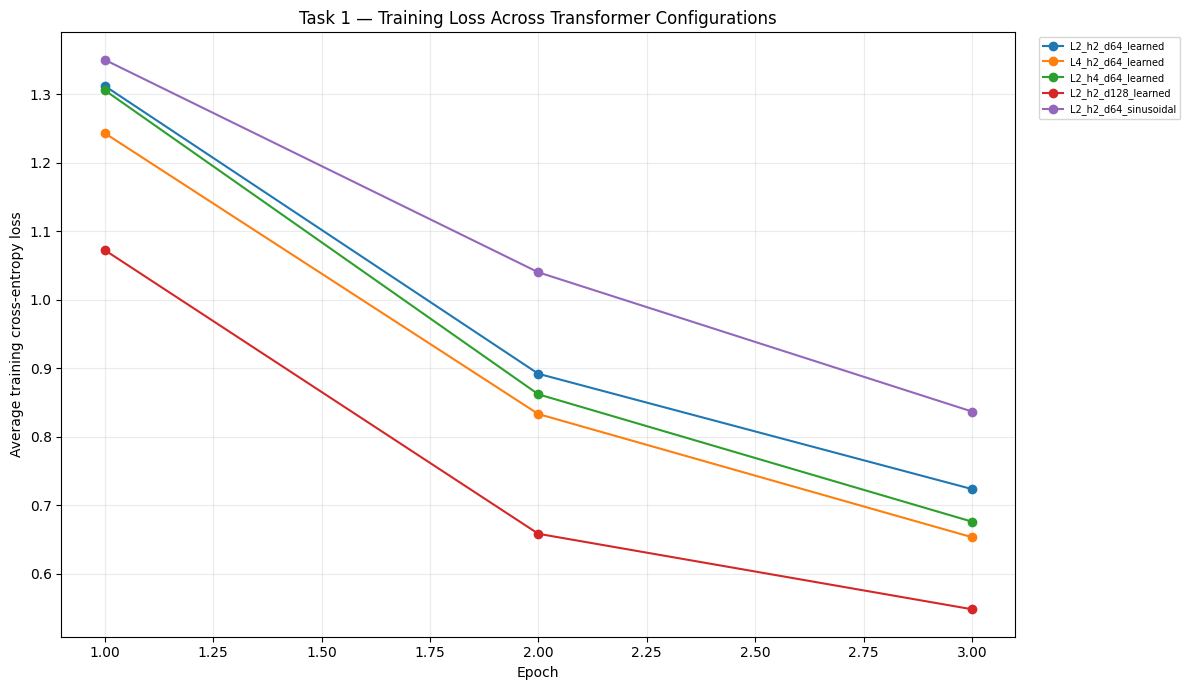

In [13]:
plt.figure(figsize=(12, 7))
for result in experiment_results:
    history = result["history"]["train_loss"]
    plt.plot(range(1, len(history) + 1), history, marker="o", linewidth=1.5, label=result["config_name"])
plt.xlabel("Epoch")
plt.ylabel("Average training cross-entropy loss")
plt.title("Task 1 — Training Loss Across Transformer Configurations")
plt.grid(alpha=0.25)
plt.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("/content/task1_training_loss_all_configs.png", dpi=180, bbox_inches="tight")
plt.show()

## 14. Test metrics table and best-model confusion matrix

The best configuration is selected using validation Macro F1. The official test split is evaluated only once for this selected model; other configurations have blank test-metric cells to avoid unnecessary repeated test evaluation.


,config_name,num_layers,num_heads,d_model,positional,epochs_run,converged,best_val_macro_f1,test_accuracy,test_macro_f1,runtime_seconds
0,L2_h2_d128_learned,2,2,128,learned,3,False,0.8342,0.8226,0.8223,10.6
1,L4_h2_d64_learned,4,2,64,learned,3,False,0.7946,nan,nan,15.7
2,L2_h4_d64_learned,2,4,64,learned,3,False,0.7873,nan,nan,10.2
3,L2_h2_d64_learned,2,2,64,learned,3,False,0.7748,nan,nan,20.7
4,L2_h2_d64_sinusoidal,2,2,64,sinusoidal,3,False,0.7286,nan,nan,10.3


Best model configuration: {'num_layers': 2, 'num_heads': 2, 'd_model': 128, 'positional': 'learned'}
Test accuracy: 0.8226
Test Macro F1: 0.8223

Classification report:
              precision    recall  f1-score   support

       World     0.8336    0.8279    0.8307      1900
      Sports     0.8756    0.9037    0.8894      1900
    Business     0.7679    0.7974    0.7823      1900
    Sci/Tech     0.8134    0.7616    0.7866      1900

    accuracy                         0.8226      7600
   macro avg     0.8226    0.8226    0.8223      7600
weighted avg     0.8226    0.8226    0.8223      7600



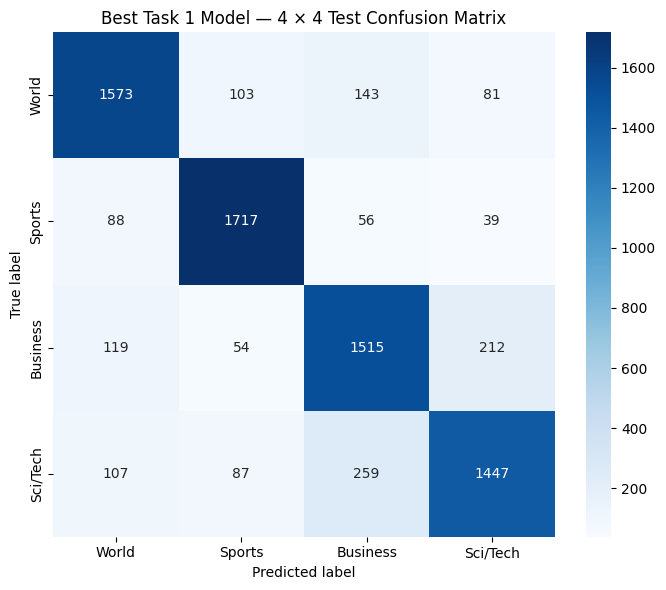

In [14]:
metric_columns = [
    "config_name", "num_layers", "num_heads", "d_model", "positional",
    "epochs_run", "converged", "best_val_macro_f1", "test_accuracy", "test_macro_f1", "runtime_seconds"
]
display(results_df[metric_columns].style.format({
    "best_val_macro_f1": "{:.4f}",
    "test_accuracy": "{:.4f}",
    "test_macro_f1": "{:.4f}",
    "runtime_seconds": "{:.1f}",
}))

print("Best model configuration:", best_model_config)
print(f"Test accuracy: {final_test_metrics['accuracy']:.4f}")
print(f"Test Macro F1: {final_test_metrics['macro_f1']:.4f}")
print("\nClassification report:")
print(classification_report(
    final_test_metrics["labels"],
    final_test_metrics["predictions"],
    target_names=LABEL_NAMES,
    digits=4,
    zero_division=0,
))

cm = confusion_matrix(final_test_metrics["labels"], final_test_metrics["predictions"], labels=[0, 1, 2, 3])
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Best Task 1 Model — 4 × 4 Test Confusion Matrix")
plt.tight_layout()
plt.savefig("/content/task1_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()


## 15. Attention heatmap: `[CLS]` attention across heads

For one test headline/description, the figure shows both (1) attention **from the `[CLS]` query** to every non-padding token and (2) attention **received by the `[CLS]` key** from every valid token in the **last encoder layer**, separately for each head. Because this is a bidirectional encoder, there is no upper-triangular causal restriction: `[CLS]` can attend to every valid token, including tokens on either side in the sequence.

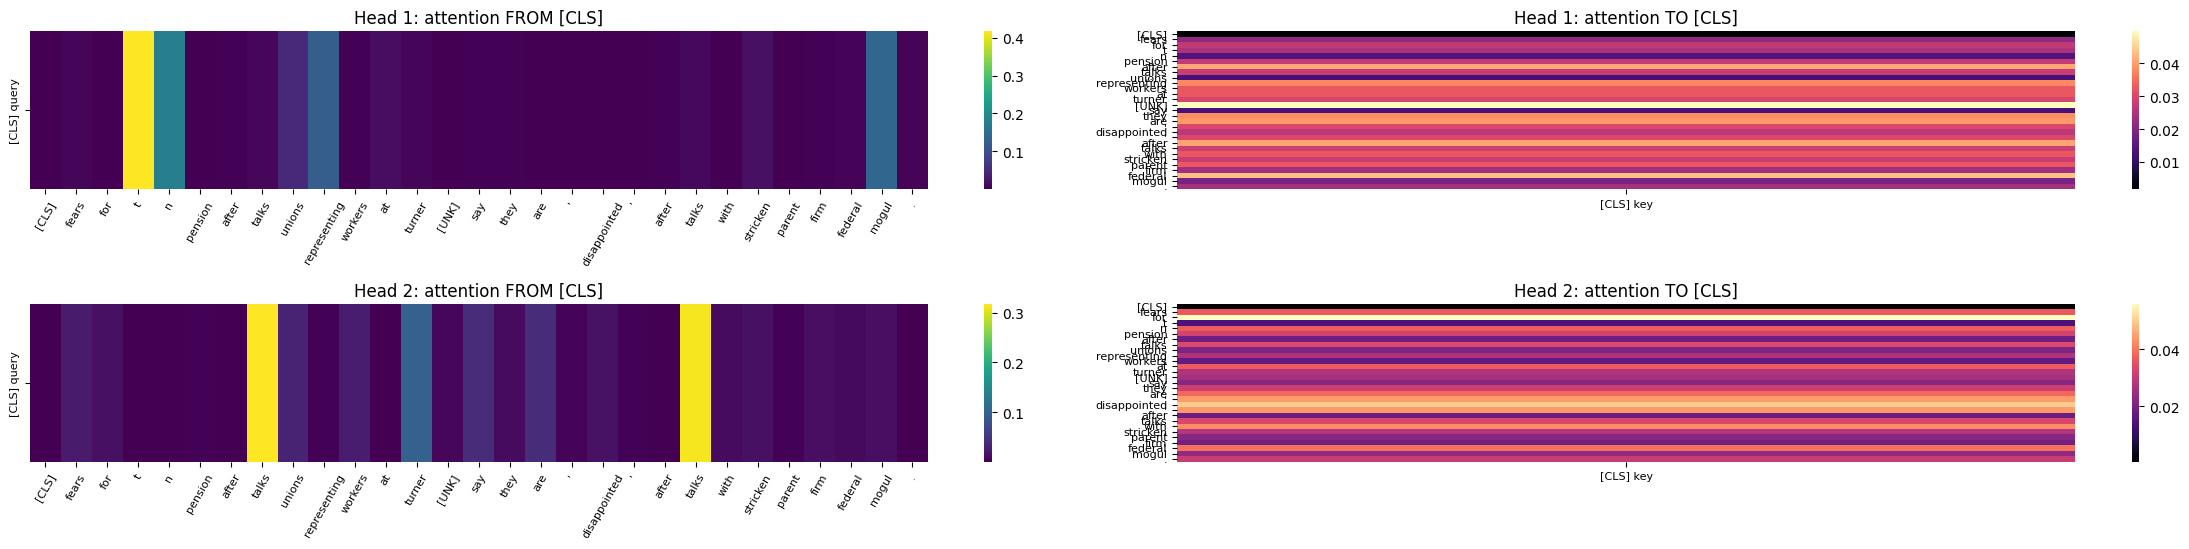

Example true category: Business
Example predicted category: Business
Tokens shown: ['[CLS]', 'fears', 'for', 't', 'n', 'pension', 'after', 'talks', 'unions', 'representing', 'workers', 'at', 'turner', '[UNK]', 'say', 'they', 'are', "'", 'disappointed', "'", 'after', 'talks', 'with', 'stricken', 'parent', 'firm', 'federal', 'mogul', '.']


In [15]:
@torch.no_grad()
def get_first_nonempty_test_example():
    ids, label = test_dataset[0]
    return ids.unsqueeze(0).to(DEVICE), int(label.item())

example_ids, example_label = get_first_nonempty_test_example()
best_model.eval()
example_logits, attention_by_layer = best_model(example_ids, return_attentions=True)
last_layer_attention = attention_by_layer[-1][0].detach().cpu().numpy()  # (heads,S,S)
valid_len = int((example_ids[0] != PAD_ID).sum().item())
example_tokens = [id_to_token.get(int(idx), UNK_TOKEN) for idx in example_ids[0, :valid_len].cpu().tolist()]

num_heads = last_layer_attention.shape[0]
fig, axes = plt.subplots(num_heads, 2, figsize=(max(12, valid_len * 0.8), 2.8 * num_heads), squeeze=False)
for head_idx in range(num_heads):
    # Row 0: [CLS] as query attending to every valid key/token.
    cls_query = last_layer_attention[head_idx, 0, :valid_len][None, :]
    sns.heatmap(
        cls_query,
        ax=axes[head_idx, 0],
        cmap="viridis",
        xticklabels=example_tokens,
        yticklabels=["[CLS] query"],
        cbar=True,
    )
    axes[head_idx, 0].set_title(f"Head {head_idx + 1}: attention FROM [CLS]")
    axes[head_idx, 0].tick_params(axis="x", labelrotation=60, labelsize=8)
    axes[head_idx, 0].tick_params(axis="y", labelsize=8)

    # Column 0: every valid query token attending TO the [CLS] key.
    cls_key = last_layer_attention[head_idx, :valid_len, 0][:, None]
    sns.heatmap(
        cls_key,
        ax=axes[head_idx, 1],
        cmap="magma",
        yticklabels=example_tokens,
        xticklabels=["[CLS] key"],
        cbar=True,
    )
    axes[head_idx, 1].set_title(f"Head {head_idx + 1}: attention TO [CLS]")
    axes[head_idx, 1].tick_params(axis="y", labelsize=8)
    axes[head_idx, 1].tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.savefig("/content/task1_cls_attention_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

predicted_label = int(example_logits.argmax(dim=-1).item())
print("Example true category:", LABEL_NAMES[example_label])
print("Example predicted category:", LABEL_NAMES[predicted_label])
print("Tokens shown:", example_tokens)

## 16. Save results and the best model

The following files are saved in the Colab working directory (`/content`). Download them from the Files pane or use the download commands below. These artifacts are useful when writing the report and submitting the notebook.

In [16]:
# Save compact experiment results and training histories.
results_df.to_csv("/content/task1_experiment_metrics.csv", index=False)
with open("/content/task1_training_histories.json", "w", encoding="utf-8") as f:
    json.dump({r["config_name"]: r["history"] for r in experiment_results}, f, indent=2)

torch.save({
    "model_state_dict": best_result["best_state"],
    "config": best_model_config,
    "vocab": vocab,
    "label_names": LABEL_NAMES,
    "max_seq_len": MAX_SEQ_LEN,
}, "/content/task1_best_encoder.pt")

print("Saved:")
for filename in [
    "task1_experiment_metrics.csv",
    "task1_training_histories.json",
    "task1_best_encoder.pt",
    "task1_training_loss_all_configs.png",
    "task1_confusion_matrix.png",
    "task1_cls_attention_heatmap.png",
]:
    path = Path("/content") / filename
    if path.exists():
        print(f"- {path} ({path.stat().st_size / 1024:.1f} KB)")

Saved:
- /content/task1_experiment_metrics.csv (0.6 KB)
- /content/task1_training_histories.json (2.0 KB)
- /content/task1_best_encoder.pt (9385.5 KB)
- /content/task1_training_loss_all_configs.png (207.0 KB)
- /content/task1_confusion_matrix.png (73.1 KB)
- /content/task1_cls_attention_heatmap.png (229.8 KB)


## 17. Discussion guide for your report

Use the actual values printed by your Colab run. Do not copy placeholder or expected metrics: performance depends on the runtime, random seed, and training duration.

### A. Effect of attention-head count (`h`)
Compare configurations that have the same `L`, `d_model`, and positional encoding but different head counts (`h=2` versus `h=4`). Discuss:
- Whether Macro F1 or test accuracy improves with more heads.
- Whether the training curves converge at a similar rate.
- How splitting a fixed `d_model` into more heads changes the per-head dimension (`d_k = d_model / h`).

### B. Effect of Transformer depth (`L`)
Compare `L=2` and `L=4` under the same `h`, `d_model`, and positional encoding. Discuss:
- Whether deeper layers improve validation Macro F1 and test metrics.
- Whether the deeper model takes longer per epoch.
- Whether training is more stable or whether deeper models need more epochs.

### C. Learned versus sinusoidal positions
Compare both positional encodings while holding the other hyperparameters constant. Discuss whether trainable positional vectors help the model learn dataset-specific word-order patterns, and whether fixed sinusoidal vectors provide comparable performance.

### D. Limitations
This is a compact BERT-style encoder trained from scratch on a balanced subset of 20,000 AG News examples. It is not pretrained BERT. The basic tokenizer is word-level and does not use subword segmentation. Mention these limitations when interpreting the results.

### E. Suggested result summary
Include in the report:
1. The metrics table for the configurations actually executed. Clearly state whether fast mode (five controlled comparisons) or the full 16-configuration grid was used.
2. Training-loss plot across configurations.
3. Best model's 4 × 4 confusion matrix and test classification report.
4. `[CLS]` attention heatmaps from the final encoder layer.
5. A short comparison of head count, depth, and positional encoding based on your measured results.

> **Before submission:** For the full hyperparameter study, set `FAST_EXPERIMENT = False` and run all cells. If you use fast mode due to Colab runtime limits, explicitly report the five configurations tested and do not claim that all 16 combinations were evaluated. Save the notebook with outputs visible. The assignment submission structure specifies `code.ipynb` and `report.pdf` inside the group's Assignment 5 folder.